In [2]:
import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt
from pathlib import Path
from shapely.geometry import box

ROOT = Path("..")      
CRASHES = ROOT / "Motor_Vehicle_Collisions_-_Crashes_20261014.csv"

YEAR = 2025
CELL = 500             # zone size in metres
METRIC_CRS = 32618     # UTM zone 18N, so distances come out in metres

# 02 Demand zones

Turns the 2025 NYPD crash records into demand: average daily injury/fatal crashes for each 500 m zone of Manhattan and each 6-hour period (d_it in the report).

- Reads: `Motor_Vehicle_Collisions_-_Crashes_20261014.csv`
- Writes: `zones.gpkg` (zones that have crashes) and `demand_d_it.csv`

In [3]:
cols = ["CRASH DATE", "CRASH TIME", "LATITUDE", "LONGITUDE", "BOROUGH",
        "NUMBER OF PERSONS INJURED", "NUMBER OF PERSONS KILLED"]
cr = pd.read_csv(CRASHES, usecols=cols)

cr["date"] = pd.to_datetime(cr["CRASH DATE"], errors="coerce")
cr = cr[cr["date"].dt.year == YEAR]
hurt = cr["NUMBER OF PERSONS INJURED"].fillna(0) + cr["NUMBER OF PERSONS KILLED"].fillna(0)
cr = cr[(hurt > 0) & cr["LATITUDE"].notna() & cr["LONGITUDE"].notna() & (cr["LATITUDE"] != 0)]   # injury/fatal, with a location

cr["hour"] = pd.to_datetime(cr["CRASH TIME"], format="%H:%M", errors="coerce").dt.hour
cr = cr.dropna(subset=["hour"])
cr["period"] = (cr["hour"] // 6).astype(int)       # 0 = 00-06, 1 = 06-12, 2 = 12-18, 3 = 18-24
print(f"{YEAR} injury/fatal crashes with coordinates (all boroughs):", len(cr))

2025 injury/fatal crashes with coordinates (all boroughs): 36347


In [4]:
pts = gpd.GeoDataFrame(cr, geometry=gpd.points_from_xy(cr["LONGITUDE"], cr["LATITUDE"]), crs=4326).to_crs(METRIC_CRS)

manhattan = ox.geocode_to_gdf("Manhattan, New York, USA").to_crs(METRIC_CRS)
outline = manhattan.geometry.union_all()

inside = pts[pts.within(outline)]
print(inside["BOROUGH"].value_counts(dropna=False))

# Same rule as the report: the crash record has to say MANHATTAN.
pts = inside[inside["BOROUGH"].astype(str).str.strip().str.upper() == "MANHATTAN"].copy()
print("Manhattan crashes used:", len(pts))

BOROUGH
MANHATTAN    5272
NaN           731
BRONX          21
Name: count, dtype: int64
Manhattan crashes used: 5272


Inside the Manhattan outline there are 5,272 crashes labelled MANHATTAN, 731 with no borough label and 21 labelled Bronx. We keep the 5,272, which matches the report's 5,270 (the two-crash difference is minor). The 731 unlabelled ones are left out, about 12% of what falls inside the outline, so that is worth a line in the limitations.

In [5]:
# 500 m grid over the outline, clipped to the shoreline.
minx, miny, maxx, maxy = outline.bounds
cells = [box(x, y, x + CELL, y + CELL)
         for x in np.arange(minx, maxx, CELL) for y in np.arange(miny, maxy, CELL)]
grid = gpd.GeoDataFrame(geometry=cells, crs=METRIC_CRS)
grid = grid[grid.intersects(outline)].copy()
grid["geometry"] = grid.intersection(outline)
grid = grid[~grid.is_empty].reset_index(drop=True)
grid["zone"] = grid.index
print("grid squares:", len(grid))

grid squares: 427


zones with crashes: 237 | crashes: 5272 | per day: 14.44


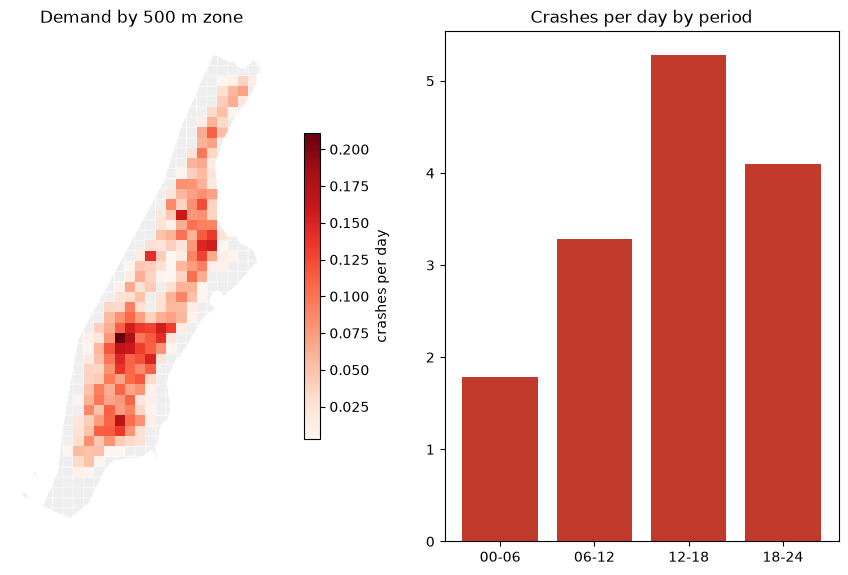

In [6]:
j = gpd.sjoin(pts, grid[["zone", "geometry"]], how="inner", predicate="within")
w = j.groupby(["zone", "period"]).size().unstack(fill_value=0).reindex(columns=[0, 1, 2, 3], fill_value=0)
d = w / 365                                       # average crashes per day, by zone and period

print("zones with crashes:", len(d), "| crashes:", int(w.values.sum()), "| per day:", round(d.values.sum(), 2))

grid[grid["zone"].isin(d.index)].to_file(ROOT / "zones.gpkg", driver="GPKG")     # only zones with demand matter downstream
d.to_csv(ROOT / "demand_d_it.csv")

fig, ax = plt.subplots(1, 2, figsize=(11, 6), gridspec_kw={"width_ratios": [1.6, 1]})
grid.plot(ax=ax[0], color="#eeeeee", edgecolor="white", linewidth=0.3)
shown = grid.join(d.sum(axis=1).rename("per_day"), how="inner")
shown.plot(ax=ax[0], column="per_day", cmap="Reds", legend=True, legend_kwds={"label": "crashes per day", "shrink": 0.6})
ax[0].set_title("Demand by 500 m zone"); ax[0].set_axis_off()
ax[1].bar(["00-06", "06-12", "12-18", "18-24"], d.sum().values, color="#c0392b")
ax[1].set_title("Crashes per day by period")
plt.tight_layout()
plt.show()

Result: 5,272 crashes, 14.44 per day, spread over 237 zones with at least one crash. The report has 5,270 crashes, 14.4 per day and 235 zones, so we are close; the zone count depends a little on where the grid starts.

The grid has more squares than the report's 268 because the outline includes parts of the rivers. Squares without crashes have no demand, so they are dropped and don't affect the model.